# Stage 2 — Model and loss

Crack segmentation and measurement project. Explanations: see the study guide.

In [3]:
# Cell 1 — Install and import
%pip install -q segmentation-models-pytorch

from pathlib import Path
import time

import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torch.nn as nn
import albumentations as A
from albumentations.pytorch import ToTensorV2
import segmentation_models_pytorch as smp

DATA_ROOT = Path("/kaggle/input")
SEED = 0
torch.manual_seed(SEED)
torch.set_num_threads(4)
print("torch", torch.__version__, "| smp", smp.__version__)

Note: you may need to restart the kernel to use updated packages.
torch 2.11.0+cpu | smp 0.5.0


In [4]:
# Cell 2 — A small batch of real training images
folders = {p.name: p for p in DATA_ROOT.rglob("*")
           if p.is_dir() and p.name in {"Images", "Images-2", "Masks"}}

def load_mask(path):
    arr = np.array(Image.open(path).convert("L"))
    return arr > (127 if arr.max() > 1 else 0)

picks = ["Volker", "Rissbilder", "GAPS384", "CRACK500"]   # training sources only
tf = A.Compose([A.Resize(256, 256), A.Normalize(), ToTensorV2()])
images, masks, names = [], [], []
for prefix in picks:
    candidates = sorted(folders["Images"].glob(f"{prefix}*.png")) + sorted(folders["Images-2"].glob(f"{prefix}*.png"))
    for path in candidates:
        mask = load_mask(folders["Masks"] / path.name)
        if mask.mean() > 0.02:                       # first image with a clearly visible crack
            out = tf(image=np.array(Image.open(path).convert("RGB")), mask=mask.astype(np.uint8))
            images.append(out["image"])
            masks.append(out["mask"].unsqueeze(0).float())
            names.append(path.name)
            break
x = torch.stack(images)      # 4 x 3 x 256 x 256
y = torch.stack(masks)       # 4 x 1 x 256 x 256
print(names)
print("x", tuple(x.shape), "| y", tuple(y.shape), f"| crack pixels {100 * y.mean():.1f}%")

['Volker_DSC01627_695_410_1138_1343.png', 'Rissbilder_for_Florian_9S6A2782_10_871_3141_3988.png', 'GAPS384_test_0005_541_1.png', 'CRACK500_20160222_080850_1281_361.png']
x (4, 3, 256, 256) | y (4, 1, 256, 256) | crack pixels 4.3%


In [6]:
# Cell 3 — Build the U-Net
model = smp.Unet(
    encoder_name="resnet34",       # the feature extractor
    encoder_weights="imagenet",    # start from weights learned on 1.2 million photos
    in_channels=3,                 # RGB input
    classes=1,                     # one output channel: crack score per pixel
)

def n_params(module):
    return sum(p.numel() for p in module.parameters())

print(f"encoder:          {n_params(model.encoder) / 1e6:5.1f} M parameters")
print(f"decoder:          {n_params(model.decoder) / 1e6:5.1f} M parameters")
print(f"segmentation head:{n_params(model.segmentation_head):8d} parameters")
print(f"total:            {n_params(model) / 1e6:5.1f} M parameters")

encoder:           21.3 M parameters
decoder:            3.2 M parameters
segmentation head:     145 parameters
total:             24.4 M parameters


In [7]:
# Cell 4 — Follow one batch through the network
model.eval()
with torch.no_grad():
    features = model.encoder(x)
    for level, f in enumerate(features):
        print(f"encoder level {level}: {tuple(f.shape)}")
    logits = model(x)
print("model output:", tuple(logits.shape))

encoder level 0: (4, 3, 256, 256)
encoder level 1: (4, 64, 128, 128)
encoder level 2: (4, 64, 64, 64)
encoder level 3: (4, 128, 32, 32)
encoder level 4: (4, 256, 16, 16)
encoder level 5: (4, 512, 8, 8)
model output: (4, 1, 256, 256)


In [8]:
# Cell 5 — From logits to probabilities
probs = torch.sigmoid(logits)
print(f"logits range: {logits.min():.2f} to {logits.max():.2f}")
print(f"probabilities: mean {probs.mean():.3f}, min {probs.min():.3f}, max {probs.max():.3f}")
print(f"pixels above 0.5 (predicted crack): {100 * (probs > 0.5).float().mean():.1f}%")

logits range: -4.99 to 0.27
probabilities: mean 0.111, min 0.007, max 0.567
pixels above 0.5 (predicted crack): 0.0%


In [9]:
# Cell 6 — Loss functions
bce_loss = nn.BCEWithLogitsLoss()

def dice_loss(logits, target, eps=1.0):
    prob = torch.sigmoid(logits)
    inter = (prob * target).sum(dim=(1, 2, 3))
    total = prob.sum(dim=(1, 2, 3)) + target.sum(dim=(1, 2, 3))
    dice = (2 * inter + eps) / (total + eps)       # 1 = perfect overlap, 0 = none
    return (1 - dice).mean()

def combined_loss(logits, target):
    return bce_loss(logits, target) + dice_loss(logits, target)

In [10]:
# Cell 7 — How each loss judges different predictions
def as_logits(pred_mask):
    return torch.where(pred_mask > 0, 8.0, -8.0)     # confident yes / no

kernel = np.ones((9, 9), np.uint8)
thick = torch.stack([torch.from_numpy(cv2.dilate(m[0].numpy().astype(np.uint8), kernel)).float()[None]
                     for m in y])

scenarios = {
    "perfect": as_logits(y),
    "all background": as_logits(torch.zeros_like(y)),
    "unsure everywhere (p = 0.5)": torch.zeros_like(y),
    "crack drawn 4 px too wide": as_logits(thick),
}
print(f"{'prediction':30s} {'pixel acc':>9s} {'BCE':>7s} {'Dice loss':>9s} {'BCE+Dice':>9s}")
for label, lg in scenarios.items():
    acc = ((lg > 0).float() == y).float().mean()
    print(f"{label:30s} {100 * acc:8.1f}% {bce_loss(lg, y):7.3f} {dice_loss(lg, y):9.3f} "
          f"{combined_loss(lg, y):9.3f}")

prediction                     pixel acc     BCE Dice loss  BCE+Dice
perfect                           100.0%   0.000     0.005     0.005
all background                     95.7%   0.342     0.999     1.341
unsure everywhere (p = 0.5)        95.7%   0.693     0.923     1.617
crack drawn 4 px too wide          93.9%   0.489     0.446     0.935


In [11]:
# Cell 8 — Sanity check: can the model learn these 4 images?
model.train()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
start = time.time()
for step in range(1, 41):
    optimizer.zero_grad()            # clear gradients from the previous step
    loss = combined_loss(model(x), y)
    loss.backward()                  # gradients: how each weight affects the loss
    optimizer.step()                 # nudge every weight to reduce the loss
    if step == 1 or step % 5 == 0:
        print(f"step {step:2d}  loss {loss.item():.3f}  ({time.time() - start:.0f} s)")

step  1  loss 1.478  (2 s)
step  5  loss 1.238  (9 s)
step 10  loss 1.005  (19 s)
step 15  loss 0.856  (28 s)
step 20  loss 0.736  (38 s)
step 25  loss 0.632  (47 s)
step 30  loss 0.545  (56 s)
step 35  loss 0.465  (65 s)
step 40  loss 0.384  (74 s)


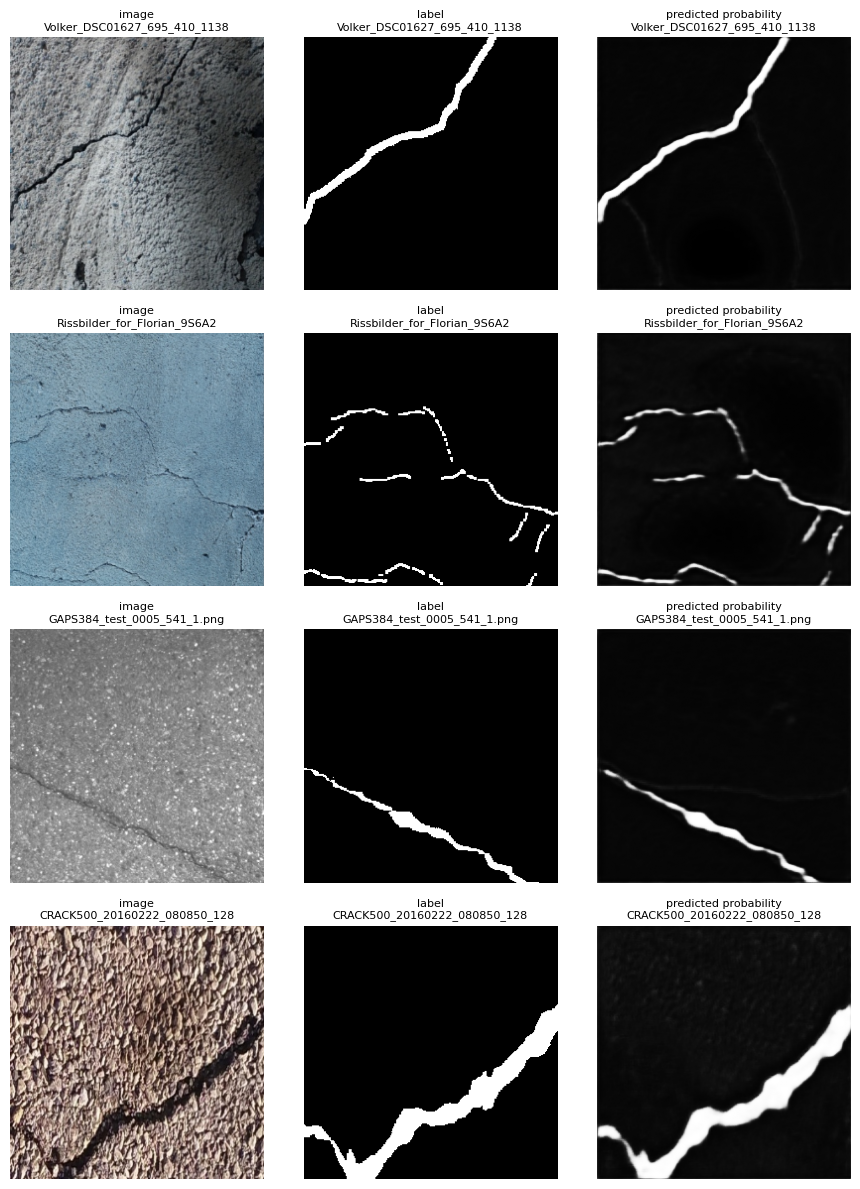

In [12]:
# Cell 9 — What the model predicts after the sanity check
model.eval()
with torch.no_grad():
    probs = torch.sigmoid(model(x))
MEAN, STD = np.array([0.485, 0.456, 0.406]), np.array([0.229, 0.224, 0.225])
fig, axes = plt.subplots(len(x), 3, figsize=(9, 3 * len(x)))
for i in range(len(x)):
    img = np.clip(x[i].permute(1, 2, 0).numpy() * STD + MEAN, 0, 1)
    for ax, (title, shown) in zip(axes[i], [("image", img), ("label", y[i, 0]),
                                            ("predicted probability", probs[i, 0])]):
        ax.imshow(shown, cmap="gray", vmin=0, vmax=1)
        ax.set_title(f"{title}\n{names[i][:28]}", fontsize=8)
        ax.axis("off")
plt.tight_layout()
plt.show()